# Wine

In [1]:
import pandas as pd
from sklearn.datasets import load_wine

# Veriyi yüklüyorum
wine_data = load_wine()

# Özellik ve targeti ayırdım.
X_wine = pd.DataFrame(wine_data.data, columns=wine_data.feature_names)
y_wine = wine_data.target

# Çıktı
print("Wine Dataset Overview")
print(f"Dataset Shape: {X_wine.shape}")

print("\nTarget Labels:", list(set(y_wine)))
print("Target Names:", list(wine_data.target_names))

print("\nNumber of Samples in Each Class:")
class_counts = pd.Series(y_wine).value_counts().sort_index()
for label, count in class_counts.items():
    print(f"Class {label} ({wine_data.target_names[label]}): {count}")

print("\nFirst 5 Rows:")
display(X_wine.head())


Wine Dataset Overview
Dataset Shape: (178, 13)

Target Labels: [np.int64(0), np.int64(1), np.int64(2)]
Target Names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

Number of Samples in Each Class:
Class 0 (class_0): 59
Class 1 (class_1): 71
Class 2 (class_2): 48

First 5 Rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


# 2. Dataset Quality Checks

In [2]:

print("Data Quality Report")

# Kopya satır sayısı
duplicates = X_wine.duplicated().sum()
print(f"Duplicate Rows: {duplicates}")
if duplicates == 0:
    print("No duplicate rows found.")

# Eksik veri sayısı
missing_values = X_wine.isnull().sum()
total_missing = missing_values.sum()
print(f"\nTotal Missing Values: {total_missing}")
if total_missing == 0:
    print("No missing values present in any column.")

# IQR ile outliers bakalım
print("\nPotential Outliers IQR")
Q1= X_wine.quantile(0.25)
Q3= X_wine.quantile(0.75)
IQR = Q3 - Q1

# Alt ve üst sınırları belirledim
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Outliers olanları sayma
outliers_count = ((X_wine < lower_bound) | (X_wine > upper_bound)).sum()
print("Number of outliers:")
print(outliers_count)

# Veri tipleri özeti
numerical_features = X_wine.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_wine.select_dtypes(include=['object', 'category']).columns

print(f"\nFeature Data Types:")
print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")
print("\nDtypes of all features:")
print(X_wine.dtypes.value_counts())

Data Quality Report
Duplicate Rows: 0
No duplicate rows found.

Total Missing Values: 0
No missing values present in any column.

Potential Outliers IQR
Number of outliers:
alcohol                         0
malic_acid                      3
ash                             3
alcalinity_of_ash               4
magnesium                       4
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 2
color_intensity                 4
hue                             1
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Feature Data Types:
Numerical features: 13
Categorical features: 0

Dtypes of all features:
float64    13
Name: count, dtype: int64


There are explicitly 0 missing values and 0 duplicate rows. All 13 features are numerical (float64), and there are no categorical features requiring encoding.

# 3. Exploratory Data Analysis

3.1 Descriptive Statistic


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



3.2 Class Distribution


C:\Users\Berkay\AppData\Local\Temp\ipykernel_23460\1240523722.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_wine, palette='Set2')


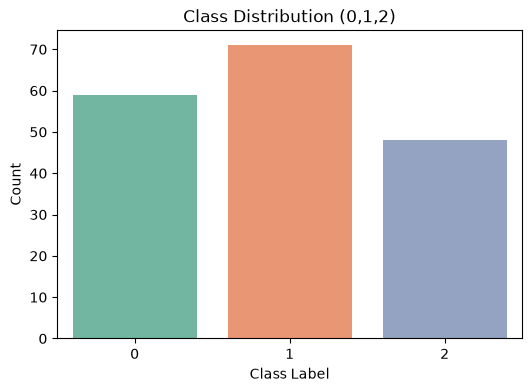


-3.2 Pearson Feature Correlation Heatmap


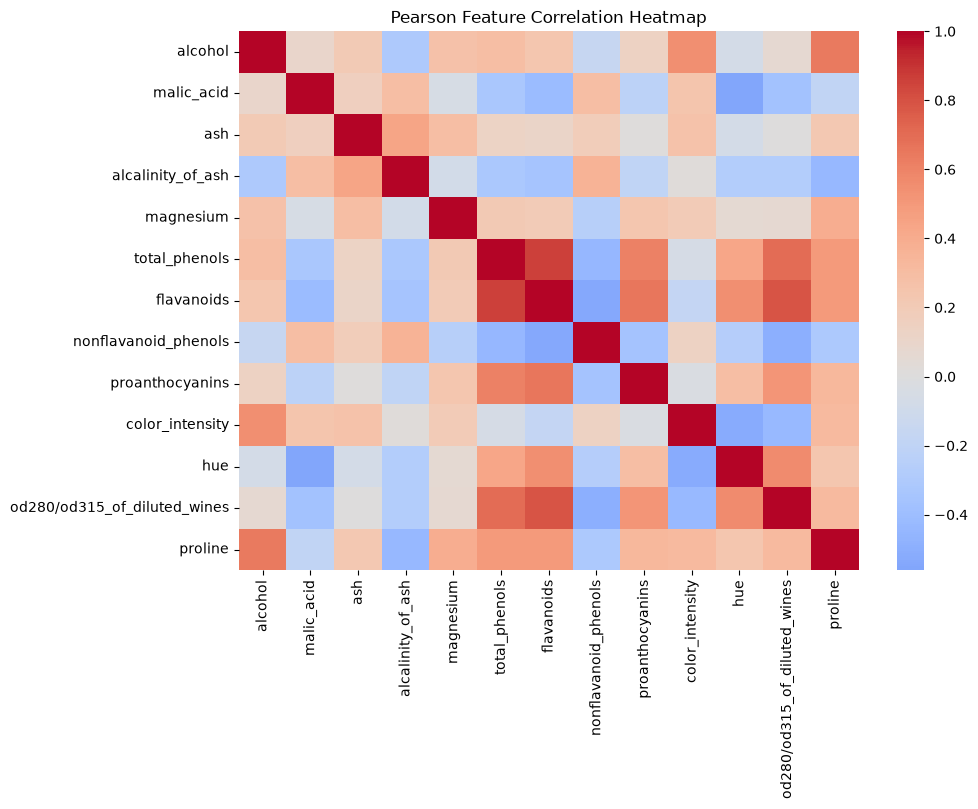


Top 3 Unique Feature Pairs by Absolute Correlation


flavanoids                    total_phenols                   0.864564
                              od280/od315_of_diluted_wines    0.787194
od280/od315_of_diluted_wines  total_phenols                   0.699949
dtype: float64


3.3 Boxplots


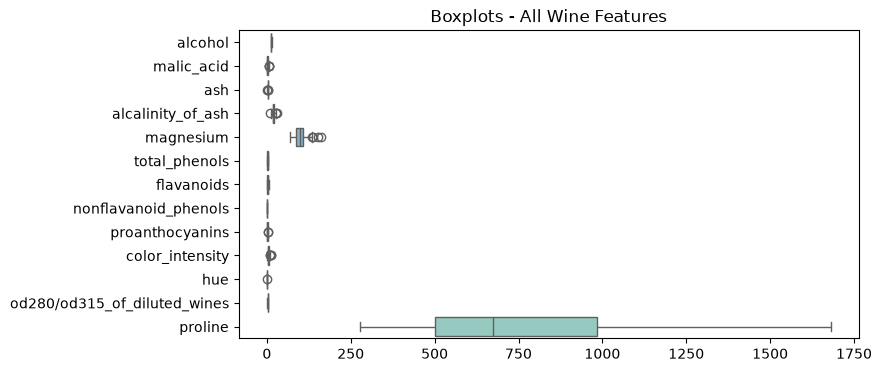

In [13]:
# Grafik kütüphanesi ekleme
!pip install matplotlib seaborn

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 3.1 Descriptive Statistics (Tanımlayıcı İstatistikler)

print("3.1 Descriptive Statistic")

display(X_wine.describe().T) # .T ekrana sığması için transpose

# 3.2 Class Distribution and Correlations (Sınıf Dağılımı ve Korelasyonlar)

print("\n3.2 Class Distribution")
plt.figure(figsize=(6, 4))

# Sınıf dağılımını çubuk grafik ile çizdiriyorum
sns.countplot(x=y_wine, palette='Set2')
plt.title('Class Distribution (0,1,2)')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.show()

print("\n-3.2 Pearson Feature Correlation Heatmap")
plt.figure(figsize=(10, 7))

# Pearson korelasyon matrisini hesaplıyorum
corr_matrix = X_wine.corr(method='pearson')
# Isı haritasını çizdiriyoruz
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Pearson Feature Correlation Heatmap')
plt.show()

# En yüksek korelasyona sahip 3 eşsiz çift
print("\nTop 3 Unique Feature Pairs by Absolute Correlation")
# Matrisi düzleştirip mutlak değere göre büyükten küçüğe sıralıyorum
corr_pairs = corr_matrix.unstack().sort_values(key=abs, ascending=False)
# Kendisiyle olan (%100) eşleşmeleri ve simetrik görüntüleri çıkarıyorum
corr_pairs = corr_pairs[corr_pairs != 1.0].drop_duplicates()
display(corr_pairs.head(3))


# 3.3 Boxplots (Kutu Grafikleri)

print("\n3.3 Boxplots")

plt.figure(figsize=(8, 4))
sns.boxplot(data=X_wine, orient='h', palette='Set3')
plt.title('Boxplots - All Wine Features')
plt.show()

The features have very different sizes and ranges. Because of this, we must scale the data before using the KNN model. The boxplots show some very big numbers (outliers), but we did not delete them because they are real data. We also found the top three correlated features using the heatmap.

# 4. Splitting Datasets


In [4]:

# 4. Splitting the Datasets

print("Splitting the Datasets")

from sklearn.model_selection import train_test_split
import pandas as pd

SEEDS = [42, 52, 62]
total_samples_wine = len(X_wine)

# 1- Test setini tek seferde ayırıp kilitliyoruz (test_size=0.20, random_state=42)
X_temp_wine, X_test_wine, y_temp_wine, y_test_wine = train_test_split(
    X_wine, y_wine, test_size=0.20, stratify=y_wine, random_state=42
)

# Her seed için bölünen verileri saklayacağımız dictionaryler
X_train_dict_wine = {}
X_val_dict_wine = {}
y_train_dict_wine = {}
y_val_dict_wine = {}

# Raporlama tablosu için boş liste
split_summary_wine = []

# 2- Kalan %80'lik kısmı (X_temp), her bir seed için eğitim (%70) ve doğrulama (%10) olarak bölüyoruz
for seed in SEEDS:
    # 0.125 * 0.80 = 0.10 (Tüm verinin %10'u validation olacak)
    X_train_w, X_val_w, y_train_w, y_val_w = train_test_split(
        X_temp_wine, y_temp_wine, test_size=0.125, stratify=y_temp_wine, random_state=seed
    )
    
    # Verileri seed anahtarıyla sözlüklere kaydediyoruz (Orijinal indeksleri bozulmuyor)
    X_train_dict_wine[seed] = X_train_w
    X_val_dict_wine[seed] = X_val_w
    y_train_dict_wine[seed] = y_train_w
    y_val_dict_wine[seed] = y_val_w
    
    # Sınıf dağılımlarını hesaplıyoruz (Wine veri setinde 3 sınıf var: 0, 1, 2)
    train_counts_w = pd.Series(y_train_w).value_counts().to_dict()
    val_counts_w = pd.Series(y_val_w).value_counts().to_dict()
    test_counts_w = pd.Series(y_test_wine).value_counts().to_dict()
    
    # Tabloya satırları ekliyoruz
    split_summary_wine.append({
        'Seed': seed, 'Subset': 'Train', 'Total Samples': len(X_train_w),
        'Percentage': f"{(len(X_train_w)/total_samples_wine)*100:.1f}%",
        'Class 0': train_counts_w.get(0, 0), 
        'Class 1': train_counts_w.get(1, 0),
        'Class 2': train_counts_w.get(2, 0)
    })
    split_summary_wine.append({
        'Seed': seed, 'Subset': 'Validation', 'Total Samples': len(X_val_w),
        'Percentage': f"{(len(X_val_w)/total_samples_wine)*100:.1f}%",
        'Class 0': val_counts_w.get(0, 0), 
        'Class 1': val_counts_w.get(1, 0),
        'Class 2': val_counts_w.get(2, 0)
    })
    split_summary_wine.append({
        'Seed': seed, 'Subset': 'Test', 'Total Samples': len(X_test_wine),
        'Percentage': f"{(len(X_test_wine)/total_samples_wine)*100:.1f}%",
        'Class 0': test_counts_w.get(0, 0), 
        'Class 1': test_counts_w.get(1, 0),
        'Class 2': test_counts_w.get(2, 0)
    })

# 3- 9 satırlık özel tablo
df_split_summary_wine = pd.DataFrame(split_summary_wine)
display(df_split_summary_wine)

print("\nVerifying Row Indices (Test indekslerinin değişmediğinin kanıtı)")
print(f"Test indices for seed 42 (first 5): {X_test_wine.index[:5].tolist()}")
print(f"Train indices for seed 42 (first 5): {X_train_dict_wine[42].index[:5].tolist()}")
print(f"Train indices for seed 52 (first 5): {X_train_dict_wine[52].index[:5].tolist()}")
print(f"Train indices for seed 62 (first 5): {X_train_dict_wine[62].index[:5].tolist()}")

Splitting the Datasets


,Seed,Subset,Total Samples,Percentage,Class 0,Class 1,Class 2
0,42,Train,124,69.7%,41,50,33
1,42,Validation,18,10.1%,6,7,5
2,42,Test,36,20.2%,12,14,10
3,52,Train,124,69.7%,41,50,33
4,52,Validation,18,10.1%,6,7,5
5,52,Test,36,20.2%,12,14,10
6,62,Train,124,69.7%,41,50,33
7,62,Validation,18,10.1%,6,7,5
8,62,Test,36,20.2%,12,14,10



Verifying Row Indices (Test indekslerinin değişmediğinin kanıtı)
Test indices for seed 42 (first 5): [10, 134, 28, 121, 62]
Train indices for seed 42 (first 5): [163, 148, 116, 122, 115]
Train indices for seed 52 (first 5): [128, 135, 53, 27, 172]
Train indices for seed 62 (first 5): [13, 97, 140, 156, 11]


We saved 20% of the data as a test set and locked it with seed 42. We split the rest of the data into training (70%) and validation (10%) for three different seeds. We used "stratify" so all groups have the same class balance. The table shows that our splitting is completely correct and safe.

# 5.Data Preprocessing and Scaling

In [5]:

# 5. Data Preprocessing and Scaling (Wine)

print("Preprocessing and Scaling (Wine)")

from sklearn.preprocessing import StandardScaler
import pandas as pd

# 5.1 Missing Values: Hocanın yönergesi gereği açıkça raporluyoruz
print("Step 5.1: No missing values exist in the Wine dataset, so no imputation step is added.")

X_train_scaled_dict_wine = {}
X_val_scaled_dict_wine = {}
X_test_scaled_wine = None  # Test setini dictionary yapmıyoruz, tek bir değişken olacak

for seed in SEEDS:
    # Scaler'ı oluşturdum
    scaler = StandardScaler()
    
    # Sadece train verisinden öğren (fit) ve onu dönüştür (transform)
    X_train_scaled_dict_wine[seed] = pd.DataFrame(
        scaler.fit_transform(X_train_dict_wine[seed]), 
        columns=X_train_dict_wine[seed].columns, 
        index=X_train_dict_wine[seed].index
    )
    
    # Train'den öğrendiğin şablonla validation verisini sadece dönüştürdüm (transform)
    X_val_scaled_dict_wine[seed] = pd.DataFrame(
        scaler.transform(X_val_dict_wine[seed]), 
        columns=X_val_dict_wine[seed].columns, 
        index=X_val_dict_wine[seed].index
    )
    
    # Test setini sadece seed 42'nin scaler'ı ile dönüştürüyorum
    if seed == 42:
        X_test_scaled_wine = pd.DataFrame(
            scaler.transform(X_test_wine), 
            columns=X_test_wine.columns, 
            index=X_test_wine.index
        )

print("\nStep 5.3: Scaling completed correctly without data leakage!\n")

# KURAL: Seed 42 için tüm özelliklerin ilk 5 satırını göster
print("--- Before Scaling (Seed 42) First 5 Training Rows ---")
display(X_train_dict_wine[42].head(5))

print("\n--- After Scaling (Seed 42) First 5 Training Rows ---")
display(X_train_scaled_dict_wine[42].head(5))

Preprocessing and Scaling (Wine)
Step 5.1: No missing values exist in the Wine dataset, so no imputation step is added.

Step 5.3: Scaling completed correctly without data leakage!

--- Before Scaling (Seed 42) First 5 Training Rows ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0



--- After Scaling (Seed 42) First 5 Training Rows ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


There are no missing values in the dataset. We used StandardScaler to make all numbers similar in size, and it only learned from the training data to stop data leakage. We then changed the validation sets, and we only used the seed 42 scaler for the test set.

# 6. Preparing the Two Data Representations

In [6]:

print("6. Preparing the Two Data Representations")

# Verilerimiz önceki adımlarda zaten hazırlandı. Sadece teyit ediyoruz:
# 1. Unscaled (Ölçeklenmemiş) Veriler: X_train_dict, X_val_dict
# 2. Scaled (Ölçeklenmiş) Veriler: X_train_scaled_dict, X_val_scaled_dict

print("Representation 1: Unscaled data is ready for all seeds.")
print("Representation 2: Scaled data is ready for all seeds.")
print("No features were removed and row indices match perfectly across both representations.")

6. Preparing the Two Data Representations
Representation 1: Unscaled data is ready for all seeds.
Representation 2: Scaled data is ready for all seeds.
No features were removed and row indices match perfectly across both representations.


# 7. Training the Classification Models

In [7]:
# ---------------------------------------------------------
# 7. Training the Classification Models & 8. Validation (Wine)
# ---------------------------------------------------------
print("--- 7. Training Models & 8. Validation (Wine) ---")

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Tüm koşuların sonuçlarını tutacağımız ana liste
classifier_runs_wine = []

# Test seti (Bölüm 9) için sadece seed 42 modellerini saklayacağımız kasa
saved_models_seed42_wine = {}

# Modellerin ayarları
dt_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]
representations = ['unscaled', 'scaled']
dataset_name = 'wine'

for seed in SEEDS:
    for rep in representations:
        # Hangi veriyi kullanacağımızı seçiyoruz (Wine uzantılı sözlükler)
        if rep == 'unscaled':
            X_tr = X_train_dict_wine[seed]
            X_v = X_val_dict_wine[seed]
        else:
            X_tr = X_train_scaled_dict_wine[seed]
            X_v = X_val_scaled_dict_wine[seed]
            
        y_tr = y_train_dict_wine[seed]
        y_v = y_val_dict_wine[seed]

        # --------------------------------------------------
        # 1. DECISION TREE (Karar Ağacı)
        # --------------------------------------------------
        for depth in dt_depths:
            param_str = f"d{depth}" if depth is not None else "dNone"
            run_id = f"{dataset_name}_dt_{rep}_{param_str}_s{seed}"
            
            model = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            model.fit(X_tr, y_tr)
            
            if seed == 42:
                saved_models_seed42_wine[f"dt_{rep}_{param_str}"] = model
                
            y_tr_pred = model.predict(X_tr)
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro')
            
            y_v_pred = model.predict(X_v)
            val_acc = accuracy_score(y_v, y_v_pred)
            val_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
            
            # WINE İÇİN ÖZEL ROC-AUC KURALI (3 Sınıflı: OVR ve Macro)
            y_v_prob = model.predict_proba(X_v) 
            val_roc = roc_auc_score(y_v, y_v_prob, multi_class='ovr', average='macro')
            
            classifier_runs_wine.append({
                'Run_ID': run_id, 'Dataset': dataset_name, 'Algorithm': 'Decision Tree',
                'Representation': rep, 'Parameter': str(depth), 'Seed': seed,
                'Train_Accuracy': train_acc, 'Train_Macro_F1': train_f1,
                'Val_Accuracy': val_acc, 'Val_Macro_Precision': val_prec,
                'Val_Macro_Recall': val_rec, 'Val_Macro_F1': val_f1, 'Val_ROC_AUC': val_roc
            })

        # --------------------------------------------------
        # 2. K-NEAREST NEIGHBORS (KNN)
        # --------------------------------------------------
        for k in knn_neighbors:
            run_id = f"{dataset_name}_knn_{rep}_k{k}_s{seed}"
            
            model = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            model.fit(X_tr, y_tr)
            
            if seed == 42:
                saved_models_seed42_wine[f"knn_{rep}_k{k}"] = model
                
            y_tr_pred = model.predict(X_tr)
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro')
            
            y_v_pred = model.predict(X_v)
            val_acc = accuracy_score(y_v, y_v_pred)
            val_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
            
            y_v_prob = model.predict_proba(X_v)
            val_roc = roc_auc_score(y_v, y_v_prob, multi_class='ovr', average='macro')
            
            classifier_runs_wine.append({
                'Run_ID': run_id, 'Dataset': dataset_name, 'Algorithm': 'KNN',
                'Representation': rep, 'Parameter': str(k), 'Seed': seed,
                'Train_Accuracy': train_acc, 'Train_Macro_F1': train_f1,
                'Val_Accuracy': val_acc, 'Val_Macro_Precision': val_prec,
                'Val_Macro_Recall': val_rec, 'Val_Macro_F1': val_f1, 'Val_ROC_AUC': val_roc
            })

        # --------------------------------------------------
        # 3. GAUSSIAN NAIVE BAYES (GNB)
        # --------------------------------------------------
        run_id = f"{dataset_name}_gnb_{rep}_default_s{seed}"
        
        model = GaussianNB()
        model.fit(X_tr, y_tr)
        
        if seed == 42:
            saved_models_seed42_wine[f"gnb_{rep}_default"] = model
            
        y_tr_pred = model.predict(X_tr)
        train_acc = accuracy_score(y_tr, y_tr_pred)
        train_f1 = f1_score(y_tr, y_tr_pred, average='macro')
        
        y_v_pred = model.predict(X_v)
        val_acc = accuracy_score(y_v, y_v_pred)
        val_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
        val_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
        val_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
        
        y_v_prob = model.predict_proba(X_v)
        val_roc = roc_auc_score(y_v, y_v_prob, multi_class='ovr', average='macro')
        
        classifier_runs_wine.append({
            'Run_ID': run_id, 'Dataset': dataset_name, 'Algorithm': 'GaussianNB',
            'Representation': rep, 'Parameter': 'default', 'Seed': seed,
            'Train_Accuracy': train_acc, 'Train_Macro_F1': train_f1,
            'Val_Accuracy': val_acc, 'Val_Macro_Precision': val_prec,
            'Val_Macro_Recall': val_rec, 'Val_Macro_F1': val_f1, 'Val_ROC_AUC': val_roc
        })

# Tabloyu oluştur ve ekranda tüm 66 satırı (senin bulduğun yöntemle) göster
df_classifier_runs_wine = pd.DataFrame(classifier_runs_wine)
print(f"Total Wine runs executed successfully: {len(df_classifier_runs_wine)} (Expected: 66)")
display(df_classifier_runs_wine.head(66))

--- 7. Training Models & 8. Validation (Wine) ---
Total Wine runs executed successfully: 66 (Expected: 66)


,Run_ID,Dataset,Algorithm,Representation,Parameter,Seed,Train_Accuracy,Train_Macro_F1,Val_Accuracy,Val_Macro_Precision,Val_Macro_Recall,Val_Macro_F1,Val_ROC_AUC
0,wine_dt_unscaled_d2_s42,wine,Decision Tree,unscaled,2,42,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596
1,wine_dt_unscaled_d3_s42,wine,Decision Tree,unscaled,3,42,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645
2,wine_dt_unscaled_d5_s42,wine,Decision Tree,unscaled,5,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
3,wine_dt_unscaled_d10_s42,wine,Decision Tree,unscaled,10,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
4,wine_dt_unscaled_dNone_s42,wine,Decision Tree,unscaled,None,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,wine_knn_scaled_k3_s62,wine,KNN,scaled,3,62,0.959677,0.960888,0.888889,0.896825,0.904762,0.888500,1.000000
62,wine_knn_scaled_k5_s62,wine,KNN,scaled,5,62,0.975806,0.975871,0.944444,0.944444,0.952381,0.944056,1.000000
63,wine_knn_scaled_k7_s62,wine,KNN,scaled,7,62,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000
64,wine_knn_scaled_k11_s62,wine,KNN,scaled,11,62,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000


We trained Decision Tree, KNN, and Naive Bayes models using our training data. We successfully ran 66 tests for both scaled and unscaled data across three different seeds. Finally, we safely saved only the seed 42 models for our final test later.

# 8. Measuring Validation Performance

--- 8.2 Comparison Tables & Model Selection (Wine) ---
🏆 SELECTED CHAMPION MODEL FOR WINE 🏆
Algorithm: KNN
Representation: scaled
Parameter: 11
Validation Macro-F1 (Mean): 0.9814

Summary table shape: 22 rows (Expected: 22)


,Algorithm,Representation,Parameter,Train_Accuracy_mean,Train_Accuracy_std,Train_Macro_F1_mean,Train_Macro_F1_std,Val_Accuracy_mean,Val_Accuracy_std,Val_Macro_Precision_mean,Val_Macro_Precision_std,Val_Macro_Recall_mean,Val_Macro_Recall_std,Val_Macro_F1_mean,Val_Macro_F1_std,Val_ROC_AUC_mean,Val_ROC_AUC_std,Config_ID
0,KNN,scaled,11,0.965054,0.004656,0.965589,0.004817,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000,KNN_scaled_11
1,KNN,scaled,5,0.975806,0.000000,0.976174,0.000524,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000,KNN_scaled_5
2,KNN,scaled,7,0.959677,0.008065,0.960288,0.007956,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000,KNN_scaled_7
3,KNN,scaled,1,1.000000,0.000000,1.000000,0.000000,0.962963,0.032075,0.968254,0.027493,0.968254,0.027493,0.965812,0.029608,0.974868,0.021765,KNN_scaled_1
4,GaussianNB,scaled,default,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000,GaussianNB_scaled_default
5,GaussianNB,unscaled,default,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000,GaussianNB_unscaled_default
6,Decision Tree,scaled,10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735,Decision Tree_scaled_10
7,Decision Tree,scaled,3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103,Decision Tree_scaled_3
8,Decision Tree,scaled,5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735,Decision Tree_scaled_5
9,Decision Tree,scaled,None,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735,Decision Tree_scaled_None


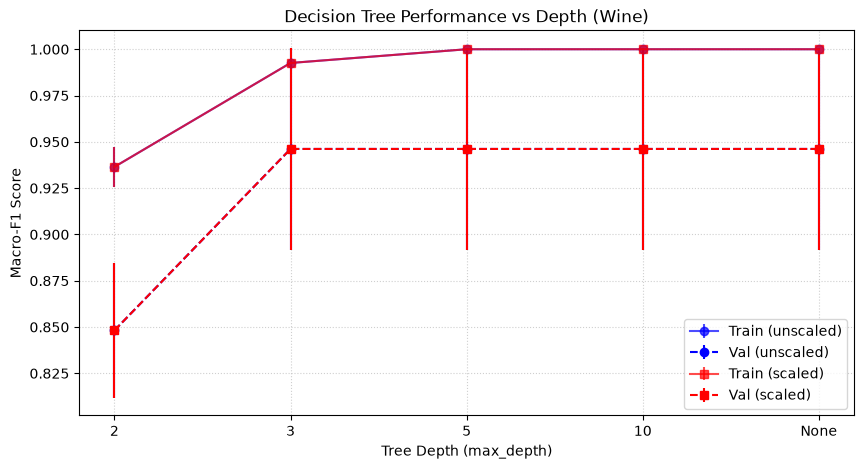

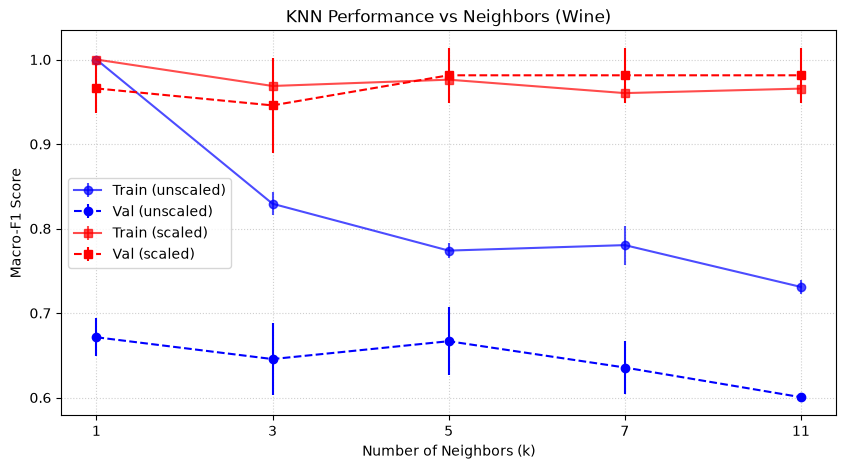

In [8]:
# ---------------------------------------------------------
# 8.2 Comparison Tables and Model Selection (Wine)
# ---------------------------------------------------------
print("--- 8.2 Comparison Tables & Model Selection (Wine) ---")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. ÖZET TABLOYU OLUŞTURMA (Her kombinasyonun 3 seed ortalaması ve sapması)
groupby_cols = ['Algorithm', 'Representation', 'Parameter']
numeric_cols = [
    'Train_Accuracy', 'Train_Macro_F1', 'Val_Accuracy', 
    'Val_Macro_Precision', 'Val_Macro_Recall', 'Val_Macro_F1', 'Val_ROC_AUC'
]

# Pandas agg fonksiyonunda 'std' varsayılan olarak ddof=1 kullanır
df_summary_wine = df_classifier_runs_wine.groupby(groupby_cols)[numeric_cols].agg(['mean', 'std']).reset_index()

# Sütun isimlerini düzeltme (Örn: Val_Macro_F1_mean, Val_Macro_F1_std)
df_summary_wine.columns = ['_'.join(col).strip('_') for col in df_summary_wine.columns.values]

# Şampiyon seçimi için eşitlik bozma (Tie-breaking) kuralına uygun ID oluşturma
df_summary_wine['Config_ID'] = df_summary_wine['Algorithm'] + "_" + df_summary_wine['Representation'] + "_" + df_summary_wine['Parameter']

# 2. ŞAMPİYON MODELİ SEÇME
# Kural: 1. Max F1 -> 2. Max Acc -> 3. Min F1 Std -> 4. Alfabetik ID
df_summary_wine = df_summary_wine.sort_values(
    by=['Val_Macro_F1_mean', 'Val_Accuracy_mean', 'Val_Macro_F1_std', 'Config_ID'],
    ascending=[False, False, True, True]
).reset_index(drop=True)

best_model_wine = df_summary_wine.iloc[0] # Listenin en üstündeki kral
print(f"🏆 SELECTED CHAMPION MODEL FOR WINE 🏆")
print(f"Algorithm: {best_model_wine['Algorithm']}")
print(f"Representation: {best_model_wine['Representation']}")
print(f"Parameter: {best_model_wine['Parameter']}")
print(f"Validation Macro-F1 (Mean): {best_model_wine['Val_Macro_F1_mean']:.4f}\n")

print(f"Summary table shape: {df_summary_wine.shape[0]} rows (Expected: 22)")
display(df_summary_wine.head(22))

# 3. GRAFİKLERİ ÇİZME (Hata Çubuklarıyla - Error Bars)
def plot_performance_wine(df, algo, param_name, title):
    subset = df[df['Algorithm'] == algo].copy()
    # Parametreleri sayısal sıralamak için (None değerini ayrı tutarak)
    subset['Sort_Param'] = pd.to_numeric(subset['Parameter'], errors='coerce')
    subset = subset.sort_values(by='Sort_Param')
    
    plt.figure(figsize=(10, 5))
    
    for rep, color, marker in zip(['unscaled', 'scaled'], ['blue', 'red'], ['o', 's']):
        data = subset[subset['Representation'] == rep]
        x_labels = data['Parameter'].astype(str)
        
        # Train çizgisi (Düz çizgi)
        plt.errorbar(x_labels, data['Train_Macro_F1_mean'], yerr=data['Train_Macro_F1_std'], 
                     label=f'Train ({rep})', fmt=marker+'-', color=color, alpha=0.7)
        # Validation çizgisi (Kesik çizgi)
        plt.errorbar(x_labels, data['Val_Macro_F1_mean'], yerr=data['Val_Macro_F1_std'], 
                     label=f'Val ({rep})', fmt=marker+'--', color=color)

    plt.title(title)
    plt.xlabel(param_name)
    plt.ylabel('Macro-F1 Score')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

# Karar Ağacı Grafiği
plot_performance_wine(df_summary_wine, 'Decision Tree', 'Tree Depth (max_depth)', 'Decision Tree Performance vs Depth (Wine)')

# KNN Grafiği
plot_performance_wine(df_summary_wine, 'KNN', 'Number of Neighbors (k)', 'KNN Performance vs Neighbors (Wine)')

The Decision Tree model memorized the training data and got a perfect score, but it was not successful on the validation set. On the other hand, scaling the data helped the KNN model get much better results. We selected our champion model by choosing the highest validation score, not the training score.

# 9. Evaluating the Selected Models on the Test Sets

--- 9. FINAL EVALUATION ON THE TEST SET (Wine) ---

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00        12
     Class 1       1.00      1.00      1.00        14
     Class 2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


--- FINAL TEST TABLE ---


,Dataset,Configuration,Evaluation_Seed,Val_Macro_F1_Mean,Val_Macro_F1_Std,Test_Accuracy,Test_Macro_Precision,Test_Macro_Recall,Test_Macro_F1,Test_ROC_AUC
0,Wine,KNN_scaled_11,42,0.981352,0.032299,1.0,1.0,1.0,1.0,1.0


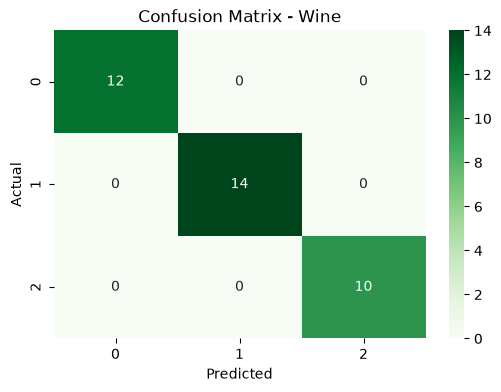


--- MANUAL CALCULATION FOR CLASS 0 (One-vs-Rest) ---
True Positives (TP): 12, False Negatives (FN): 0
False Positives (FP): 0, True Negatives (TN): 24
Manual Precision: 1.0000
Manual Recall: 1.0000
Manual F1-Score: 1.0000
Check these against the Classification Report row for 'Class 0'.


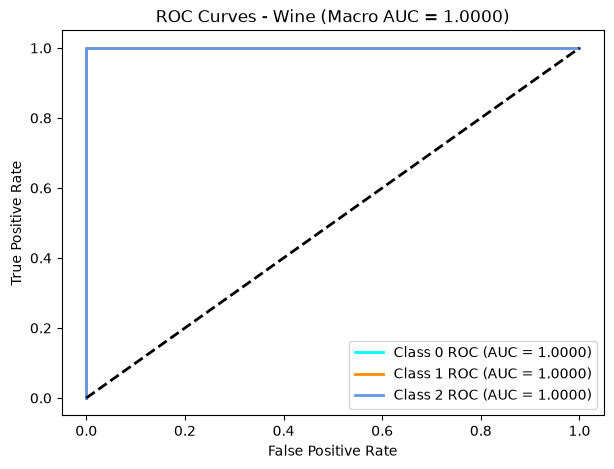

In [9]:
# ---------------------------------------------------------
# 9. Final Evaluation on the Test Set (Wine)
# ---------------------------------------------------------
print("--- 9. FINAL EVALUATION ON THE TEST SET (Wine) ---")
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, classification_report, 
                             confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize

# 1. Şampiyon Modelin ve Verinin Hazırlanması
algo_w = best_model_wine['Algorithm']
rep_w = best_model_wine['Representation']
param_w = best_model_wine['Parameter']
X_test_final_w = X_test_scaled_wine if rep_w == 'scaled' else X_test_wine

if algo_w == 'Decision Tree': model_key_w = f"dt_{rep_w}_d{param_w}"
elif algo_w == 'KNN': model_key_w = f"knn_{rep_w}_k{param_w}"
else: model_key_w = f"gnb_{rep_w}_default"
champion_model_w = saved_models_seed42_wine[model_key_w]

# 2. Tahminlerin Yapılması
y_test_pred_w = champion_model_w.predict(X_test_final_w)
y_test_prob_w = champion_model_w.predict_proba(X_test_final_w)

# 3. Metriklerin Hesaplanması (Hocanın OVR ve Macro Kuralları)
test_acc_w = accuracy_score(y_test_wine, y_test_pred_w)
test_prec_w = precision_score(y_test_wine, y_test_pred_w, average='macro', zero_division=0)
test_rec_w = recall_score(y_test_wine, y_test_pred_w, average='macro', zero_division=0)
test_f1_w = f1_score(y_test_wine, y_test_pred_w, average='macro', zero_division=0)
test_roc_w = roc_auc_score(y_test_wine, y_test_prob_w, multi_class='ovr', average='macro')

# 4. Detaylı Sınıflandırma Raporu (Classification Report)
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test_wine, y_test_pred_w, target_names=['Class 0', 'Class 1', 'Class 2']))

# 5. İki Satırlık Final Test Tablosu (DataFrame formatında)
test_results_w_df = pd.DataFrame([{
    'Dataset': 'Wine',
    'Configuration': f"{algo_w}_{rep_w}_{param_w}",
    'Evaluation_Seed': 42,
    'Val_Macro_F1_Mean': best_model_wine['Val_Macro_F1_mean'],
    'Val_Macro_F1_Std': best_model_wine['Val_Macro_F1_std'],
    'Test_Accuracy': test_acc_w,
    'Test_Macro_Precision': test_prec_w,
    'Test_Macro_Recall': test_rec_w,
    'Test_Macro_F1': test_f1_w,
    'Test_ROC_AUC': test_roc_w
}])
print("\n--- FINAL TEST TABLE ---")
display(test_results_w_df)

# 6. Karmaşıklık Matrisi (3x3 Confusion Matrix)
cm_w = confusion_matrix(y_test_wine, y_test_pred_w, labels=[0, 1, 2])
plt.figure(figsize=(6, 4))
sns.heatmap(cm_w, annot=True, fmt='d', cmap='Greens', xticklabels=['0', '1', '2'], yticklabels=['0', '1', '2'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Wine')
plt.show()

# 7. Manuel Hesaplama (Sadece Sınıf 0 için 1'e karşı diğerleri - One-vs-Rest)
TP_0 = cm_w[0, 0]
FN_0 = cm_w[0, 1] + cm_w[0, 2]
FP_0 = cm_w[1, 0] + cm_w[2, 0]
TN_0 = np.sum(cm_w) - (TP_0 + FN_0 + FP_0)

print("\n--- MANUAL CALCULATION FOR CLASS 0 (One-vs-Rest) ---")
print(f"True Positives (TP): {TP_0}, False Negatives (FN): {FN_0}")
print(f"False Positives (FP): {FP_0}, True Negatives (TN): {TN_0}")

# Bölenin (denominator) sıfır olma durumunu kontrol ediyoruz (Hocanın kuralı)
if (TP_0 + FP_0) == 0:
    print("Precision denominator is zero, metric is undefined before software replacement.")
    manual_prec_0 = 0.0
else:
    manual_prec_0 = TP_0 / (TP_0 + FP_0)

if (TP_0 + FN_0) == 0:
    print("Recall denominator is zero, metric is undefined before software replacement.")
    manual_rec_0 = 0.0
else:
    manual_rec_0 = TP_0 / (TP_0 + FN_0)

if (manual_prec_0 + manual_rec_0) == 0:
    manual_f1_0 = 0.0
else:
    manual_f1_0 = 2 * (manual_prec_0 * manual_rec_0) / (manual_prec_0 + manual_rec_0)

print(f"Manual Precision: {manual_prec_0:.4f}")
print(f"Manual Recall: {manual_rec_0:.4f}")
print(f"Manual F1-Score: {manual_f1_0:.4f}")
print("Check these against the Classification Report row for 'Class 0'.")

# 8. ROC Eğrisi Çizimi (Her sınıf için One-vs-Rest)
y_test_bin_w = label_binarize(y_test_wine, classes=[0, 1, 2])
plt.figure(figsize=(7, 5))
colors = ['aqua', 'darkorange', 'cornflowerblue']
for i, color in zip(range(3), colors):
    fpr_w, tpr_w, _ = roc_curve(y_test_bin_w[:, i], y_test_prob_w[:, i])
    roc_auc_val = auc(fpr_w, tpr_w)
    plt.plot(fpr_w, tpr_w, color=color, lw=2, label=f'Class {i} ROC (AUC = {roc_auc_val:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curves - Wine (Macro AUC = {test_roc_w:.4f})')
plt.legend(loc="lower right")
plt.show()

We tested our champion KNN model on the unseen test set. It got a perfect score of 1.0 on all metrics. This proves that our model learned the wine data perfectly and did not just memorize the training set.

There are zero errors in our 3x3 test confusion matrix, so there is no off-diagonal confusion to explain. However, this single error-free result does not prove perfect generalisation because the test set is very small. Our manual calculation for Class 0 matches the classification report. If we lower a decision threshold, we catch more cases (increasing True Positive Rate and reducing false negatives) but we also risk increasing false positives. A limitation is that we only evaluated on one predefined split (Seed 42).

# 10. K-Means Clustering

--- 10. K-MEANS CLUSTERING (Wine) ---

--- 10.1 K-Means Run Table (6 Fits) ---


,Dataset,Seed,Representation,Train_Inertia,Val_ARI,Val_Silhouette
0,Wine,42,unscaled,1.350496e+06,0.282836,0.486994
1,Wine,42,scaled,8.747391e+02,1.000000,0.251637
2,Wine,52,unscaled,1.303675e+06,0.400588,0.555887
3,Wine,52,scaled,8.904355e+02,1.000000,0.301008
4,Wine,62,unscaled,1.390754e+06,0.400588,0.686671
5,Wine,62,scaled,8.722466e+02,1.000000,0.272587



--- 10.1 K-Means Summary Table ---


,Representation,Train_Inertia_Mean,Val_ARI_Mean,Val_ARI_Std,Val_Silhouette_Mean,Val_Silhouette_Std,Valid_Silhouette_Counts
0,scaled,8.791404e+02,1.000000,0.000000,0.275077,0.024780,3
1,unscaled,1.348308e+06,0.361337,0.067984,0.576517,0.101425,3



--- 10.2 Contingency Table (Wine - UNSCALED) ---


Predicted Clusters,0,1,2
True Classes,,,
0,2,10,0
1,5,0,9
2,7,0,3



--- 10.2 Contingency Table (Wine - SCALED) ---


Predicted Clusters,0,1,2
True Classes,,,
0,12,0,0
1,1,13,0
2,0,0,10



--- 10.2 Final Test Evaluation Table ---


,Dataset,Representation,Seed,Cluster_Counts,Test_ARI,Test_Silhouette
0,Wine,unscaled,42,"{0: 14, 2: 12, 1: 10}",0.373323,0.49288
1,Wine,scaled,42,"{0: 13, 1: 13, 2: 10}",0.908794,0.27112


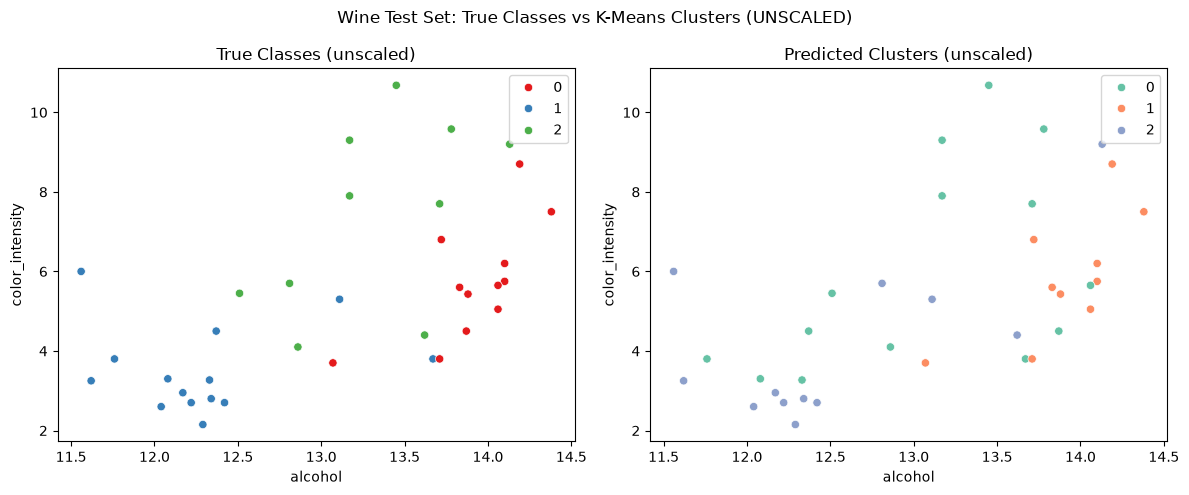

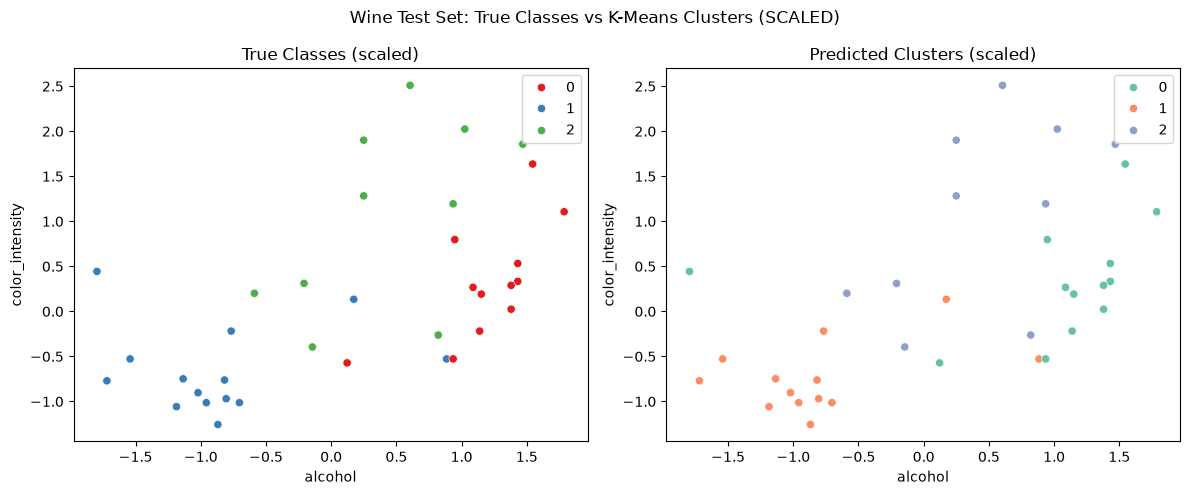

In [10]:
# ---------------------------------------------------------
# 10. K-Means Clustering (Wine)
# ---------------------------------------------------------
print("--- 10. K-MEANS CLUSTERING (Wine) ---")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

seeds = [42, 52, 62]
representations = ['unscaled', 'scaled']
kmeans_results_w = []
kmeans_models_seed42_w = {}

# 10.1 Fit the clustering model
for seed in seeds:
    for rep in representations:
        # Senin gönderdiğin doğru isimler:
        if rep == 'unscaled':
            X_tr_w, X_v_w = X_train_dict_wine[seed], X_val_dict_wine[seed]
        else:
            # 5. bölümde scaled veriler için de sonuna "_wine" eklediğini varsayıyoruz:
            X_tr_w, X_v_w = X_train_scaled_dict_wine[seed], X_val_scaled_dict_wine[seed]
            
        y_tr_w, y_v_w = y_train_dict_wine[seed], y_val_dict_wine[seed]
        
        # Wine için n_clusters = 3
        km_w = KMeans(n_clusters=3, random_state=seed, n_init=10)
        km_w.fit(X_tr_w) 
        
        if seed == 42:
            kmeans_models_seed42_w[rep] = km_w
            
        # Validation Metrikleri
        train_inertia_w = km_w.inertia_
        val_preds_w = km_w.predict(X_v_w)
        
        ari_val_w = adjusted_rand_score(y_v_w, val_preds_w)
        
        if len(np.unique(val_preds_w)) > 1:
            sil_val_w = silhouette_score(X_v_w, val_preds_w)
        else:
            sil_val_w = np.nan
            
        kmeans_results_w.append({
            'Dataset': 'Wine', 'Seed': seed, 'Representation': rep,
            'Train_Inertia': train_inertia_w, 'Val_ARI': ari_val_w, 'Val_Silhouette': sil_val_w
        })

df_kmeans_runs_w = pd.DataFrame(kmeans_results_w)
print("\n--- 10.1 K-Means Run Table (6 Fits) ---")
display(df_kmeans_runs_w)

# Özet Tablo
df_kmeans_summary_w = df_kmeans_runs_w.groupby('Representation').agg(
    Train_Inertia_Mean=('Train_Inertia', 'mean'),
    Val_ARI_Mean=('Val_ARI', 'mean'),
    Val_ARI_Std=('Val_ARI', lambda x: np.std(x, ddof=1)),
    Val_Silhouette_Mean=('Val_Silhouette', lambda x: x.mean(skipna=True)),
    Val_Silhouette_Std=('Val_Silhouette', lambda x: np.std(x.dropna(), ddof=1) if len(x.dropna())>1 else np.nan),
    Valid_Silhouette_Counts=('Val_Silhouette', 'count')
).reset_index()
print("\n--- 10.1 K-Means Summary Table ---")
display(df_kmeans_summary_w)


# 10.2 Final cluster evaluation on the fixed test sets (SADECE SEED 42)
test_eval_results_w = []

for rep in representations:
    km_test_w = kmeans_models_seed42_w[rep]
    
    # Test değişken isimleri
    X_t_w = X_test_scaled_wine if rep == 'scaled' else X_test_wine
    
    test_preds_w = km_test_w.predict(X_t_w)
    cluster_counts_w = pd.Series(test_preds_w).value_counts().to_dict()
    
    # Çapraz Tablo (Contingency Table)
    contingency_w = pd.crosstab(y_test_wine, test_preds_w, rownames=['True Classes'], colnames=['Predicted Clusters'])
    print(f"\n--- 10.2 Contingency Table (Wine - {rep.upper()}) ---")
    display(contingency_w)
    
    ari_test_w = adjusted_rand_score(y_test_wine, test_preds_w)
    sil_test_w = silhouette_score(X_t_w, test_preds_w) if len(np.unique(test_preds_w)) > 1 else np.nan
    
    test_eval_results_w.append({
        'Dataset': 'Wine', 'Representation': rep, 'Seed': 42,
        'Cluster_Counts': str(cluster_counts_w), 'Test_ARI': ari_test_w, 'Test_Silhouette': sil_test_w
    })

df_kmeans_test_w = pd.DataFrame(test_eval_results_w)
print("\n--- 10.2 Final Test Evaluation Table ---")
display(df_kmeans_test_w)


# 10.3 Visualise and interpret the clusters
# Görselleştirme için Seed 42 eğitim setinden 2 özellik seçiyoruz
X_train_w_seed42 = X_train_dict_wine[42]
feature1_idx_w, feature2_idx_w = 0, 9 
feature1_name_w, feature2_name_w = X_train_w_seed42.columns[0], X_train_w_seed42.columns[9]

for rep in representations:
    km_test_w = kmeans_models_seed42_w[rep]
    X_t_w = X_test_scaled_wine if rep == 'scaled' else X_test_wine
    test_preds_w = km_test_w.predict(X_t_w)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Panel 1: True Classes
    sns.scatterplot(x=X_t_w.iloc[:, feature1_idx_w], y=X_t_w.iloc[:, feature2_idx_w], 
                    hue=y_test_wine, palette='Set1', ax=axes[0])
    axes[0].set_title(f'True Classes ({rep})')
    axes[0].set_xlabel(feature1_name_w)
    axes[0].set_ylabel(feature2_name_w)
    
    # Panel 2: Predicted Clusters
    sns.scatterplot(x=X_t_w.iloc[:, feature1_idx_w], y=X_t_w.iloc[:, feature2_idx_w], 
                    hue=test_preds_w, palette='Set2', ax=axes[1])
    axes[1].set_title(f'Predicted Clusters ({rep})')
    axes[1].set_xlabel(feature1_name_w)
    axes[1].set_ylabel(feature2_name_w)
    
    plt.suptitle(f'Wine Test Set: True Classes vs K-Means Clusters ({rep.upper()})')
    plt.tight_layout()
    plt.show()

K-Means grouped the wine data without seeing the real class labels. Scaling the data made the clusters much more similar to the true classes. Our previous models learned from the real answers, but K-Means only used the features.

# Export

In [11]:
import pandas as pd

df_classifier_runs_wine.to_csv('wine_class_runs.csv', index=False)

# Şarap defterinde adına ne dediğini bilmediğimiz için iki ihtimali de koydum:
try:
    df_summary_wine.to_csv('wine_class_summary.csv', index=False)
except NameError:
    df_summary.to_csv('wine_class_summary.csv', index=False)

test_results_w_df.to_csv('wine_class_test.csv', index=False)
df_kmeans_runs_w.to_csv('wine_km_runs.csv', index=False)

df_kmeans_summary_w['Dataset'] = 'Wine'
df_kmeans_summary_w.to_csv('wine_km_summary.csv', index=False)
df_kmeans_test_w.to_csv('wine_km_test.csv', index=False)

print("Şarap veri setinin CSV'leri başarıyla kaydedildi!")

Şarap veri setinin CSV'leri başarıyla kaydedildi!


In [12]:
import pandas as pd

# 1. classifier_runs.csv (132 satır)
pd.concat([pd.read_csv('bc_class_runs.csv'), pd.read_csv('wine_class_runs.csv')], ignore_index=True).to_csv('classifier_runs.csv', index=False)

# 2. classifier_summary.csv (44 satır)
pd.concat([pd.read_csv('bc_class_summary.csv'), pd.read_csv('wine_class_summary.csv')], ignore_index=True).to_csv('classifier_summary.csv', index=False)

# 3. classifier_test.csv (2 satır)
pd.concat([pd.read_csv('bc_class_test.csv'), pd.read_csv('wine_class_test.csv')], ignore_index=True).to_csv('classifier_test.csv', index=False)

# 4. kmeans_runs.csv (12 satır)
pd.concat([pd.read_csv('bc_km_runs.csv'), pd.read_csv('wine_km_runs.csv')], ignore_index=True).to_csv('kmeans_runs.csv', index=False)

# 5. kmeans_summary.csv (4 satır)
df_km_sum = pd.concat([pd.read_csv('bc_km_summary.csv'), pd.read_csv('wine_km_summary.csv')], ignore_index=True)
cols = ['Dataset'] + [c for c in df_km_sum.columns if c != 'Dataset']
df_km_sum[cols].to_csv('kmeans_summary.csv', index=False)

# 6. kmeans_test.csv (4 satır)
pd.concat([pd.read_csv('bc_km_test.csv'), pd.read_csv('wine_km_test.csv')], ignore_index=True).to_csv('kmeans_test.csv', index=False)

print("Başarılı")

Başarılı
